# POLITSKY24 Dataset Accessing and Testing

In [2]:
import os
import pandas as pd

from pathlib import Path

# CHANGE THIS TO THE PATH WHERE THE DATASET IS LOCATED
data_path = Path("D:/thesis-repo/Thesis_Repository/data")

In [2]:
# Access the parquet files in the data path

parquet_files = list(data_path.glob("*.parquet"))
parquet_files

[WindowsPath('D:/thesis-repo/Thesis_Repository/data/human_annotated_validation_stance_relevancy_dataset (post-target entity pairs).parquet'),
 WindowsPath('D:/thesis-repo/Thesis_Repository/data/human_annotated_validation_stance_relevancy_dataset (query-post stance relevancy pairs).parquet'),
 WindowsPath('D:/thesis-repo/Thesis_Repository/data/human_annotated_validation_user_stance_dataset.parquet'),
 WindowsPath('D:/thesis-repo/Thesis_Repository/data/llm_annotated_full_user_stance_dataset.parquet'),
 WindowsPath('D:/thesis-repo/Thesis_Repository/data/llm_annotated_validation_user_stance_dataset.parquet'),
 WindowsPath('D:/thesis-repo/Thesis_Repository/data/user_network_dataset.parquet'),
 WindowsPath('D:/thesis-repo/Thesis_Repository/data/user_post_history_dataset.parquet'),
 WindowsPath('D:/thesis-repo/Thesis_Repository/data/user_post_list_for_stance_detection.parquet')]

In [3]:
import polars as pl

# Load each dataset manually into individual variables
user_network_df = pl.read_parquet(str(data_path / "user_network_dataset.parquet"))
user_post_history_df = pl.read_parquet(str(data_path / "user_post_history_dataset.parquet"))
user_post_list_df = pl.read_parquet(str(data_path / "user_post_list_for_stance_detection.parquet"))

# Stance label datasets
llm_full_stance_df = pl.read_parquet(str(data_path / "llm_annotated_full_user_stance_dataset.parquet"))
llm_val_stance_df = pl.read_parquet(str(data_path / "llm_annotated_validation_user_stance_dataset.parquet"))
human_val_stance_df = pl.read_parquet(str(data_path / "human_annotated_validation_user_stance_dataset.parquet"))

# Stance relevancy datasets (Note: surround filename strings in quotes)
human_val_relevancy_post_df = pl.read_parquet(
    str(data_path / "human_annotated_validation_stance_relevancy_dataset (post-target entity pairs).parquet")
)
human_val_relevancy_query_df = pl.read_parquet(
    str(data_path / "human_annotated_validation_stance_relevancy_dataset (query-post stance relevancy pairs).parquet")
)

## Dataset File Inspection

In [4]:
user_network_df.schema

Schema([('SourceUserId', Int64),
        ('TargetUserId', Int64),
        ('InteractionType', String),
        ('Count', Int64)])

In [5]:
user_network_df

SourceUserId,TargetUserId,InteractionType,Count
i64,i64,str,i64
9,9,"""Like""",1
9,9,"""Quote""",42
9,9,"""Repost""",4
9,10,"""Quote""",2
9,2549,"""Quote""",1
…,…,…,…
401391,398769,"""Like""",2
401391,398831,"""Quote""",1
401391,401391,"""Like""",3


In [6]:
# Check number of rows in user_network_df

user_network_df.shape[0]

1676895

In [7]:
user_post_history_df.schema

Schema([('PostId', Int64),
        ('UserId', Int64),
        ('PostTime', String),
        ('Content', String),
        ('Hashtags', List(String)),
        ('Languages', List(String)),
        ('Mentions', List(Int64)),
        ('IsRepost', Boolean),
        ('SourceUserId', Int64),
        ('IsQuote', Boolean),
        ('QuoteId', Int64),
        ('QuoteUserId', Int64),
        ('QuoteContent', String),
        ('IsReply', Boolean),
        ('ParentId', Int64),
        ('ParentUserId', Int64)])

In [13]:
user_post_history_df.shape[0]

18416787

In [8]:
user_post_history_df.select(pl.all().n_unique()).to_dicts()[0]

{'PostId': 14830231,
 'UserId': 8561,
 'PostTime': 18230517,
 'Content': 13138778,
 'Hashtags': 285770,
 'Languages': 1193,
 'Mentions': 88178,
 'IsRepost': 2,
 'SourceUserId': 217858,
 'IsQuote': 2,
 'QuoteId': 975337,
 'QuoteUserId': 105488,
 'QuoteContent': 910916,
 'IsReply': 2,
 'ParentId': 5472655,
 'ParentUserId': 291653}

In [12]:
# Check user post content 
user_post_history_df.select("Content").head()

Content
str
"""it’s a tragedy of the commons.…"
"""Notícia da @anonymous ""Xi Jin…"
"""Have you run it by the Godless…"
"""This! This is the energy we ne…"
"""WATCH: Trending Stories: Gas P…"


In [12]:
# Exact duplicate rows (list columns may need to be dropped/converted first)
user_post_history_df.is_duplicated().sum()

# Rows sharing a PostId
dupes = user_post_history_df.filter(pl.col("PostId").is_duplicated())
dupes.sort("PostId").head(20)

PostId,UserId,PostTime,Content,Hashtags,Languages,Mentions,IsRepost,SourceUserId,IsQuote,QuoteId,QuoteUserId,QuoteContent,IsReply,ParentId,ParentUserId
i64,i64,str,str,list[str],list[str],list[i64],bool,i64,bool,i64,i64,str,bool,i64,i64
18,16171,"""2023-12-03T01:11:35.122Z""","""The end of Moorevember coincid…",[],"[""en""]",[],true,7,false,-1,-1,"""""",false,-1,-1
18,71390,"""2023-12-04T22:26:06.295Z""","""The end of Moorevember coincid…",[],"[""en""]",[],true,7,false,-1,-1,"""""",false,-1,-1
47,9,"""2023-06-22T00:48:37.165Z""","""I used a Chrome/Edge extension…",[],[],[],false,9,false,-1,-1,"""""",false,15691770,343645
47,285903,"""2023-06-22T00:49:34.781Z""","""I used a Chrome/Edge extension…",[],[],[],true,9,false,-1,-1,"""""",false,15691770,343645
279,9,"""2023-07-06T17:04:05.906Z""","""Should be required that PD off…",[],"[""en""]",[],false,9,false,-1,-1,"""""",false,4244240,90714
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
999,141415,"""2023-10-03T01:52:13.292Z""","""Let's talk about how domestic …",[],"[""en""]",[],true,9,false,-1,-1,"""""",false,-1,-1
1000,90924,"""2023-10-03T01:47:26.282Z""","""Going along with Sheryl's post…",[],"[""en""]",[],true,9,false,-1,-1,"""""",true,999,9
1000,9,"""2023-10-03T00:58:13.600Z""","""Going along with Sheryl's post…",[],"[""en""]",[],false,9,false,-1,-1,"""""",true,999,9


In [13]:
user_post_history_df["IsReply"].value_counts()

IsReply,count
bool,u32
false,11509179
true,6907608


In [14]:
# Non-replies that have content in ParentUserId
falseReplies = user_post_history_df.filter(
    (pl.col("IsReply") == "false") & (pl.col("ParentUserId") != -1)
    )
falseReplies.head()

PostId,UserId,PostTime,Content,Hashtags,Languages,Mentions,IsRepost,SourceUserId,IsQuote,QuoteId,QuoteUserId,QuoteContent,IsReply,ParentId,ParentUserId
i64,i64,str,str,list[str],list[str],list[i64],bool,i64,bool,i64,i64,str,bool,i64,i64
10727556,235242,"""2024-11-19T23:11:37.530Z""","""Because a LOT of these people …",[],"[""en""]",[],false,235242,false,-1,-1,"""""",false,12143282,268404
7583443,163361,"""2024-11-19T23:10:37.854Z""","""I'm trying to get used to it""",[],"[""en""]",[],false,163361,false,-1,-1,"""""",false,8475193,183152
8501377,183843,"""2024-11-19T23:08:13.424Z""","""What do you expect from a lose…",[],"[""en""]",[],false,183843,false,-1,-1,"""""",false,3826921,81362
10102388,221773,"""2024-11-19T23:07:03.508Z""","""ty comrade ❤️ op is on some ve…",[],"[""en""]",[],false,221773,false,-1,-1,"""""",false,13234926,290109
8060256,171717,"""2024-11-19T23:05:44.594Z""","""""",[],"[""en""]",[],false,171717,false,-1,-1,"""""",false,17883018,395662


In [15]:
# Non-reposts all have SourceUserIds equal to UserId (original author)
falseRepost = user_post_history_df.filter(
    (pl.col("IsRepost") == "false") & (pl.col("SourceUserId") != -1)
    )
falseRepost.head()

PostId,UserId,PostTime,Content,Hashtags,Languages,Mentions,IsRepost,SourceUserId,IsQuote,QuoteId,QuoteUserId,QuoteContent,IsReply,ParentId,ParentUserId
i64,i64,str,str,list[str],list[str],list[i64],bool,i64,bool,i64,i64,str,bool,i64,i64
7840946,167406,"""2024-11-19T23:12:12.092Z""","""it’s a tragedy of the commons.…",[],"[""en""]",[],false,167406,false,-1,-1,"""""",true,15792425,345622
17079336,377198,"""2024-11-19T23:12:11Z""","""Notícia da @anonymous ""Xi Jin…",[],[],[],false,377198,false,-1,-1,"""""",false,-1,-1
9179962,196837,"""2024-11-19T23:12:11.298Z""","""Have you run it by the Godless…",[],"[""en""]",[],false,196837,false,-1,-1,"""""",true,15458353,336741
2108430,45089,"""2024-11-19T23:12:11.084Z""","""This! This is the energy we ne…",[],"[""en""]",[],false,45089,true,2109954,45144,"""WATCH: “You’re a baby shit.” …",false,-1,-1
4231604,90172,"""2024-11-19T23:12:10Z""","""WATCH: Trending Stories: Gas P…",[],[],[],false,90172,false,-1,-1,"""""",false,-1,-1


In [16]:
falseQuotes = user_post_history_df.filter(
    (pl.col("IsQuote") == "false") & (pl.col("QuoteUserId") != -1)
    )
falseQuotes.head()

PostId,UserId,PostTime,Content,Hashtags,Languages,Mentions,IsRepost,SourceUserId,IsQuote,QuoteId,QuoteUserId,QuoteContent,IsReply,ParentId,ParentUserId
i64,i64,str,str,list[str],list[str],list[i64],bool,i64,bool,i64,i64,str,bool,i64,i64


In [17]:
user_post_history_df.shape

(18416787, 16)

In [18]:
user_post_list_df.schema

Schema([('UserId', Int64), ('PostIdList', List(Int64))])

In [19]:
llm_full_stance_df.schema

Schema([('UserId', Int64),
        ('TargetEntity', String),
        ('Context', List(String)),
        ('LLMAnswerContent', String),
        ('LLMAnswerUsage', String),
        ('SourcePosts', List(String)),
        ('Spans', List(String)),
        ('Reason', String),
        ('StanceLabel', String),
        ('ConfidenceLevel', Float64)])

In [22]:
llm_full_stance_df.shape[0]

16044

In [23]:
# Check the number of confidence levels above a certain threshold (e.g., 0.8) in the LLM full stance dataset
print(llm_full_stance_df.filter(pl.col("ConfidenceLevel") >= 0.8).shape)
print(llm_full_stance_df.filter(pl.col("ConfidenceLevel") <= 0.5).shape)
print(llm_full_stance_df.filter((pl.col("ConfidenceLevel") >= 0.5) & (pl.col("ConfidenceLevel") < 0.8)).shape)

(10681, 10)
(14, 10)
(402, 10)


In [20]:
# Get number of unique values in the stance labbel column
llm_full_stance_df.select(pl.col("StanceLabel").n_unique()).to_dicts

<bound method DataFrame.to_dicts of shape: (1, 1)
┌─────────────┐
│ StanceLabel │
│ ---         │
│ u32         │
╞═════════════╡
│ 3           │
└─────────────┘>

In [21]:
# Get the count of each stance label using the value_counts() method
stance_counts = llm_full_stance_df["StanceLabel"].value_counts()
stance_counts

StanceLabel,count
str,u32
"""Favor""",3071
"""Against""",7832
"""Neither""",5141


In [22]:
llm_full_stance_df.head()

UserId,TargetEntity,Context,LLMAnswerContent,LLMAnswerUsage,SourcePosts,Spans,Reason,StanceLabel,ConfidenceLevel
i64,str,list[str],str,str,list[str],list[str],str,str,f64
9,"""Harris""","[""Assuming Harris is the pick. Biden might have endorsed her but I sure as shit hope there's been arrangements to make her the nominee with no fuss."", ""I mean so do I, there's several people I'd want over Harris. That's...not the same as refusing to vote for or support Harris in THIS election. Someone criticizing Harris for specific positions does not automatically equal ""will not vote for her"""", … ""Jill Stein is trash and cannot be trusted. https://anonymous""]","""{ ""source_tweets"": [ …","""{'input_tokens': 888, 'output_…","[""Assuming Harris is the pick. Biden might have endorsed her but I sure as shit hope there's been arrangements to make her the nominee with no fuss."", ""I mean so do I, there's several people I'd want over Harris. That's...not the same as refusing to vote for or support Harris in THIS election."", … ""Cannot express how badly this whole 'Dump Biden' thing could go if it also pulls in Harris""]","[""hope there's been arrangements to make her the nominee with no fuss"", ""not the same as refusing to vote for or support Harris in THIS election"", … ""Cannot express how badly this whole 'Dump Biden' thing could go if it also pulls in Harris""]","""The user expresses a preferenc…","""Favor""",0.85
9,"""Trump""","[""Gonna fucking Battle Royale us into a Trump presidency"", ""I don't see how you read ""We are withholding our endorsement out of fear that, should he win, Donald Trump will retaliate against our newspaper"" as anything but a giant ""VOTE KAMALA HARRIS!!!!!!!!"" statement."", … ""Hell I'm still seeing BRUCE SPRINGSTEEN takes that are ""too bad he went woke and liberal!""""]","""{ ""source_tweets"": [ …","""{'input_tokens': 810, 'output_…","[""Gonna fucking Battle Royale us into a Trump presidency"", ""I don't see how you read ""We are withholding our endorsement out of fear that, should he win, Donald Trump will retaliate against our newspaper"" as anything but a giant ""VOTE KAMALA HARRIS!!!!!!!!"" statement."", … ""Any undecided voter who's paid even the slightest attention is a Trump voter trying to justify their vote.""]","[""Gonna fucking Battle Royale us into a Trump presidency"", ""We are withholding our endorsement out of fear that, should he win, Donald Trump will retaliate against our newspaper"", … ""Any undecided voter who's paid even the slightest attention is a Trump voter trying to justify their vote""]","""The tweets express a critical …","""Against""",0.95
10,"""Harris""","[""Kamala/Harris"", ""Kamala Harris is very good at this."", … ""Republicans attacks against Kamala thus far: - She's hot - She enjoys laughing - She's quirky""]","""{ ""source_tweets"": [ …","""{'input_tokens': 803, 'output_…","[""Kamala Harris is very good at this."", ""I think Kamala is going to win."", … ""They need to run against Elon Musk, Peter Thiel, David Sacks and the rest of these white nationalist billionaires who oppose unions, democracy, and anything which gives working people a say.""]","[""Kamala Harris is very good at this."", ""I think Kamala is going to win."", … ""run against Elon Musk, Peter Thiel, David Sacks and the rest of these white nationalist billionaires""]","""The tweets express strong supp…","""Favor""",0.95
10,"""Trump""","[""Not to get too political on here, but I really hope Donald Trump does not become president again."", ""Nothing but respect for my president 🥥🌴🥥🌴"", … ""AP still has Trump up""]","""{ ""source_tweets"": [""Not t…","""{'input_tokens': 808, 'output_…","[""Not to get too political on here, but I really hope Donald Trump does not become president again."", ""Not to get too political on here, but I really hope that Donald Trump does not win the presidential election."", ""If Donald Trump wins the presidential election after going full-fascist, I think that will be quite bad

In [23]:
llm_val_stance_df.schema


Schema([('UserId', Int64),
        ('TargetEntity', String),
        ('Context', List(String)),
        ('LLMAnswerContent', String),
        ('LLMAnswerUsage', String),
        ('SourcePosts', List(String)),
        ('Spans', List(String)),
        ('Reason', String),
        ('StanceLabel', String),
        ('ConfidenceLevel', Float64)])

In [24]:
human_val_stance_df.schema

Schema([('UserId', Int64), ('Trump', String), ('Harris', String)])

In [25]:
human_val_relevancy_post_df.schema

Schema([('PostId', Int64), ('Trump', Int64), ('Harris', Int64)])

In [26]:
human_val_relevancy_query_df.schema

Schema([('Query', String),
        ('PostId', Int64),
        ('StanceRelevanceLabel', String)])

## User Network Checking

In [78]:
user_network_df.shape[0]

1676895

In [62]:
# Get the count for all interaction types in the user_network_df

interaction_counts = user_network_df.group_by("InteractionType").agg(pl.count()).sort("count", descending=True)
interaction_counts


C:\Users\andre\AppData\Local\Temp\ipykernel_32124\4114211605.py:3: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  interaction_counts = user_network_df.group_by("InteractionType").agg(pl.count()).sort("count", descending=True)


InteractionType,count
str,u32
"""Like""",991317
"""Repost""",525080
"""Quote""",160498


In [73]:
# Get the count of unique users and the number of interaction types they have participated in
unique_user_interaction_counts = user_network_df.group_by("SourceUserId").agg(
    pl.col("InteractionType").n_unique().alias("InteractionTypeCount")
)
unique_user_interaction_counts

SourceUserId,InteractionTypeCount
i64,u32
252867,1
42879,2
254180,3
14431,3
188522,2
…,…
220605,3
276944,2
304600,2


In [79]:
per_user = user_network_df.group_by("SourceUserId").agg(pl.len().alias("n_interactions"))
per_user.describe()

statistic,SourceUserId,n_interactions
str,f64,f64
"""count""",8255.0,8255.0
"""null_count""",0.0,0.0
"""mean""",199922.27232,203.136887
"""std""",116896.815487,277.230345
"""min""",9.0,1.0
"""25%""",97688.0,34.0
"""50%""",198496.0,105.0
"""75%""",302788.0,252.0
"""max""",401391.0,3158.0


## Graph Creation Testing

The code under this section of the notebook is untested and unverified. Double check before being tested.

Simple idea of how we create the data needed for the GNN: User Network Graph creation (likes and reposts) --> Connect this to the LLM full stance using the user id. <br>
    - Verify if they have the same id types (int64) and if they can be connect to each other

In [24]:
import polars as pl

core = user_post_history_df["UserId"].unique()

reposts = (
    user_post_history_df
    .filter(pl.col("IsRepost"))
    .filter(pl.col("SourceUserId").is_in(core)) # keep core users only
    .filter(pl.col("UserId") != pl.col("SourceUserId"))  # drop self-loops
    .group_by("UserId", "SourceUserId")
    .agg(pl.len().alias("weight"))
    .rename({"UserId": "src", "SourceUserId": "dst"})
)

C:\Users\andre\AppData\Local\Temp\ipykernel_80864\2874847685.py:8: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  .filter(pl.col("SourceUserId").is_in(core)) # keep core users only


In [25]:
reposts

src,dst,weight
i64,i64,u32
372290,89682,1
399299,125916,2
188907,398103,1
255402,115408,1
73585,84421,2
…,…,…
107716,321436,2
115408,308729,1
348360,199739,2


In [26]:
net = pl.read_parquet(str(data_path / "user_network_dataset.parquet"))  # use the actual filename/format from Zenodo
likes = (
    net.filter(pl.col("InteractionType") == "Like")  # adjust column names to match the file
    .select(src="SourceUserId", dst="TargetUserId", weight="Count")
)

In [27]:
likes

src,dst,weight
i64,i64,i64
9,9,1
9,13873,1
9,14511,1
9,62997,1
9,92773,3
…,…,…
401391,385828,4
401391,392266,1
401391,394655,1


Also do the same for quotes to test all possible interactions (also replies but would have to manually derive the connections in `user_post_history`)

In [28]:
quotes = (
    net.filter(pl.col("InteractionType") == "Quote")
    .select(src="SourceUserId", dst="TargetUserId", weight="Count")
)

In [29]:
quotes

src,dst,weight
i64,i64,i64
9,9,42
9,10,2
9,2549,1
9,3125,1
9,4109,1
…,…,…
401391,384107,3
401391,384773,1
401391,398501,2


In [30]:
replies = (
    user_post_history_df
    .filter(pl.col("IsReply"))
    .filter(pl.col("ParentUserId").is_in(core))
    .filter(pl.col("UserId") != pl.col("ParentUserId"))
    .group_by("UserId", "ParentUserId")
    .agg(pl.len().alias("weight"))
    .rename({"UserId": "src", "ParentUserId": "dst"})
)

C:\Users\andre\AppData\Local\Temp\ipykernel_80864\411258742.py:4: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  .filter(pl.col("ParentUserId").is_in(core))


In [31]:
import torch

nodes = core.sort()
idx = {u: i for i, u in enumerate(nodes.to_list())}

def to_edge_index(edges):
    s = [idx[u] for u in edges["src"]]
    d = [idx[u] for u in edges["dst"]]
    return torch.tensor([s, d]), torch.tensor(edges["weight"].to_list(), dtype=torch.float)

edge_index, edge_weight = to_edge_index(likes)  # or reposts

#### Build graph using NetworkX

In [32]:
# NOTE: For now, the graph construction is separate for each interaction type
# We can convert this to a single multi-relational graph later on if needed

In [33]:
import networkx as nx

def build_graph(df: pl.DataFrame) -> nx.DiGraph:
    G = nx.DiGraph()
    G.add_weighted_edges_from(
        df.select("src", "dst", "weight").iter_rows(),
        weight="weight"
    )
    return G

In [34]:
reposts_graph = build_graph(reposts)
likes_graph = build_graph(likes)
quotes_graph = build_graph(quotes)
replies_graph = build_graph(replies)

**Attach stance labels**

In [35]:
llm = pl.read_parquet(str(data_path / "llm_annotated_full_user_stance_dataset.parquet"))

In [36]:
print(llm["TargetEntity"].value_counts())
print(llm["StanceLabel"].value_counts())
print(llm["ConfidenceLevel"].value_counts())

shape: (2, 2)
┌──────────────┬───────┐
│ TargetEntity ┆ count │
│ ---          ┆ ---   │
│ str          ┆ u32   │
╞══════════════╪═══════╡
│ Trump        ┆ 8022  │
│ Harris       ┆ 8022  │
└──────────────┴───────┘
shape: (3, 2)
┌─────────────┬───────┐
│ StanceLabel ┆ count │
│ ---         ┆ ---   │
│ str         ┆ u32   │
╞═════════════╪═══════╡
│ Neither     ┆ 5141  │
│ Against     ┆ 7832  │
│ Favor       ┆ 3071  │
└─────────────┴───────┘
shape: (13, 2)
┌─────────────────┬───────┐
│ ConfidenceLevel ┆ count │
│ ---             ┆ ---   │
│ f64             ┆ u32   │
╞═════════════════╪═══════╡
│ 0.98            ┆ 323   │
│ 0.85            ┆ 886   │
│ 0.75            ┆ 25    │
│ 0.8             ┆ 145   │
│ 0.7             ┆ 300   │
│ …               ┆ …     │
│ 1.0             ┆ 1     │
│ 0.9             ┆ 2003  │
│ 0.5             ┆ 14    │
│ 0.6             ┆ 61    │
│ 0.65            ┆ 2     │
└─────────────────┴───────┘


In [37]:
llm_stances = (
    llm.select("UserId", "TargetEntity", "StanceLabel")
    .pivot(
        on="TargetEntity",
        index="UserId",
        values=["StanceLabel"],
        aggregate_function="first"
    )
)
llm_stances.head()

UserId,Harris,Trump
i64,str,str
9,"""Favor""","""Against"""
10,"""Favor""","""Against"""
49,"""Against""","""Against"""
105,"""Neither""","""Against"""
144,"""Against""","""Against"""


In [38]:
# Get the aggregate count of TargetEntities and StanceLabels
aggregated_count_labels = (
    llm.group_by("TargetEntity", "StanceLabel")
    .agg(pl.count("StanceLabel").alias("count"))
    .sort("count", descending=True)
)
aggregated_count_labels


TargetEntity,StanceLabel,count
str,str,u32
"""Trump""","""Against""",6759
"""Harris""","""Neither""",4223
"""Harris""","""Favor""",2726
"""Harris""","""Against""",1073
"""Trump""","""Neither""",918
"""Trump""","""Favor""",345


In [39]:
attrs = {
    r["UserId"]: {"Trump": r["Trump"], "Harris": r["Harris"]}
    for r in llm_stances.iter_rows(named=True)
}

In [40]:
nx.set_node_attributes(reposts_graph, attrs)
nx.set_node_attributes(likes_graph, attrs)
nx.set_node_attributes(quotes_graph, attrs)
nx.set_node_attributes(replies_graph, attrs)

In [41]:
interaction_graphs = [reposts_graph, likes_graph, quotes_graph, replies_graph]
graph_names = ["Reposts", "Likes", "Quotes", "Replies"]
stance_users = set(llm["UserId"].unique()) 

for G in interaction_graphs:
    graph_users = set(G.nodes())

    labeled_nodes = sum(1 for n in G if G.nodes[n].get("Trump") is not None or G.nodes[n].get("Harris") is not None)
    unlabeled_nodes = G.number_of_nodes() - labeled_nodes

    print(f"Graph: {graph_names[interaction_graphs.index(G)]}")
    print("--------------------------------------------------------------")
    print(f"{labeled_nodes}/{G.number_of_nodes()} nodes have a Trump or Harris label") # made this more general since the count before is just the same with both entities
    print(f"{unlabeled_nodes}/{G.number_of_nodes()} nodes are unlabeled") # users in the graph data are not in the stance dataset
    print(f"{len(stance_users - graph_users)} users in the stance dataset are not in the graph data") # users with stances that never interacted with that type of interaction
    print("--------------------------------------------------------------")

Graph: Reposts
--------------------------------------------------------------
7678/8164 nodes have a Trump or Harris label
486/8164 nodes are unlabeled
344 users in the stance dataset are not in the graph data
--------------------------------------------------------------
Graph: Likes
--------------------------------------------------------------
7937/8454 nodes have a Trump or Harris label
517/8454 nodes are unlabeled
85 users in the stance dataset are not in the graph data
--------------------------------------------------------------
Graph: Quotes
--------------------------------------------------------------
6873/7315 nodes have a Trump or Harris label
442/7315 nodes are unlabeled
1149 users in the stance dataset are not in the graph data
--------------------------------------------------------------
Graph: Replies
--------------------------------------------------------------
7768/8241 nodes have a Trump or Harris label
473/8241 nodes are unlabeled
254 users in the stance dataset 

Since there are users that interact with users involved in the POLITISKY24 dataset, we can try to implement a semi-supervised ml model using a GNN to determine the stances of such users based on their structure in the graph. This might also prove the theories for majority illusion and homophily.

In [42]:
llm.schema

Schema([('UserId', Int64),
        ('TargetEntity', String),
        ('Context', List(String)),
        ('LLMAnswerContent', String),
        ('LLMAnswerUsage', String),
        ('SourcePosts', List(String)),
        ('Spans', List(String)),
        ('Reason', String),
        ('StanceLabel', String),
        ('ConfidenceLevel', Float64)])

In [43]:
# Check for duplicate stance labels for the same user and target entity
duplicate_count = llm.group_by(["UserId", "TargetEntity"]).len().filter(pl.col("len") > 1).height
print(f"Duplicate stance labels for the same user and target entity: {duplicate_count}")

# Check for missing values in the TargetEntity and StanceLabel columns
missing_count = llm.filter(
    pl.col("TargetEntity").is_null() 
    | pl.col("StanceLabel").is_null()
    | (pl.col("TargetEntity") == "")
    | (pl.col("StanceLabel") == "")
).height

print(f"Rows missing TargetEntity or StanceLabel: {missing_count}")

Duplicate stance labels for the same user and target entity: 0
Rows missing TargetEntity or StanceLabel: 0


#### Visualization

NetworkX visualization library can get messy with a large amount of nodes and edges, best use the following recommended libraries, or others not mentioned here:
- gephi (export with `nx.write_gexf(graph, "graph.gexf)`)
- ForceAtlas2 (separate clusters better)
- cosmograph (GPU-accelerated interactable view)

In [44]:
import os
import networkx as nx


def category(attrs):
    t, h = attrs.get("Trump"), attrs.get("Harris")

    if t is None:
        return "Unlabeled"
    if t == "Favor":
        return "Pro-Trump"
    if h == "Favor":
        return "Pro-Harris"
    if t == "Against":
        return "Anti-Trump"
    if h == "Against":
        return "Anti-Harris"

    return "Neither"


def export_gephi(G, path, nodes=None, max_nodes=None):
    # Select an explicit subset of nodes
    if nodes is not None:
        selected_nodes = set(nodes)
        subgraph = G.subgraph(selected_nodes).copy()
    else:
        subgraph = G.copy()

    # Optionally keep only the highest-degree nodes
    if max_nodes is not None and subgraph.number_of_nodes() > max_nodes:
        highest_degree = sorted(
            subgraph.degree,
            key=lambda item: item[1],
            reverse=True
        )[:max_nodes]

        selected_nodes = [node for node, degree in highest_degree]
        subgraph = subgraph.subgraph(selected_nodes).copy()

    H = nx.DiGraph() if subgraph.is_directed() else nx.Graph()

    for node, attrs in subgraph.nodes(data=True):
        H.add_node(
            str(node),
            Trump=str(attrs.get("Trump") or "None"),
            Harris=str(attrs.get("Harris") or "None"),
            category=category(attrs)
        )

    H.add_edges_from(
        (str(source), str(target))
        for source, target in subgraph.edges()
    )

    output_directory = os.path.dirname(path)
    if output_directory:
        os.makedirs(output_directory, exist_ok=True)

    nx.write_gexf(H, path)

In [45]:
graphs = {
    "reposts": reposts_graph,
    "likes": likes_graph,
    "quotes": quotes_graph,
    "replies": replies_graph,
}

for name, graph in graphs.items():
    export_gephi(
        graph,
        f"graph_visual/{name}_top100.gexf", # try 100 for this since 500 runs slow
        max_nodes=100 
    )

## Link Prediction Testing

In [1]:
!py -m pip install torch-geometric

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.3 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.3 MB 2.5 MB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.3 MB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 1.6 MB/s  0:00:00

   ---------------------------------------- 0/9 [xxhash]
   ---- ----------------------------------- 1/9 [propcache]
   -------- ------------------------------- 2/9 [multidict]
   ------------- -------------------------- 3/9 [frozenlist]
   ---------------------- ----------------- 5/9 [yarl]
   ---------------------- ----------------- 5/9 [yarl]
   -------------------------- ------------- 6/9 [aiosignal]
   -------------------------- ------------- 6/9 [aiosignal]
   ------------------------------- -------- 7/9 [aiohttp]
   ------------------------------- -------- 7/9 [aiohttp]
   ------------------------------- -------- 7/9 [aio


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import importlib
from gnn_link_prediction import run_link_prediction
import gnn_link_prediction  # Replace with your module name

# Modify the source file externally, then run:
importlib.reload(gnn_link_prediction)


<module 'gnn_link_prediction' from 'd:\\thesis-repo\\Thesis_Repository\\politisky\\gnn_link_prediction.py'>

In [ ]:
# ---------- 5. Run on all four graphs (in the notebook) ----------
import polars as pl
from gnn_link_prediction import run_link_prediction

results = [
    run_link_prediction(g, n_nodes=1000, name=n)
    for g, n in zip([reposts_graph, quotes_graph],
                    ["Reposts", "Quotes"])
]

## Community Detection Testing

### Using Word Cloud

This is to check first the gist of what users are talking about, from overall discussions to top users with most posts down to individual users.

In [5]:
!py -m pip install wordcloud


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

In [5]:
text = user_post_history_df.select("Content")
text

Content
str
"""it’s a tragedy of the commons.…"
"""Notícia da @anonymous ""Xi Jin…"
"""Have you run it by the Godless…"
"""This! This is the energy we ne…"
"""WATCH: Trending Stories: Gas P…"
…
"""I’m skeptical. PROVE to me he…"
"""reskeet if you think trans wom…"
"""can’t say this on the other ap…"


In [6]:
# Check format of text
text.item(0, 0)

'it’s a tragedy of the commons. so. anyone and everyone that ‘flies’ is a fracker. no matter how selectively they choose which science stuff to “believe” or not “believe”. if you fly you are a fracker.'

**Set configurations**

In [91]:
# Configurations (edit if necessary)
USER_COL = "UserId"
TEXT_COL = "Content"
LANG_COL = "Languages"
REPOST_COL = "IsRepost"
HASHTAG_COL = "Hashtags"

LANG = "en" # keep only english tweets
KEEP_REPOSTS = False # do not keep reposts
USE_HASHTAGS = False # exclude hashtags for now
KEEP_ELECTION = False # exclude election related words for now

MIN_POSTS = 5  # a user needs at least this many usable posts
MAX_USER_SHARE = 0.3 # drop words used by more than this share of users

MAX_POSTS_PER_USER = 200  # cap per user, so heavy posters do not dominate or use all memory
N_BACKGROUND_USERS = 5000  # random users used as the "what is normal vocabulary" reference

TOP_USERS = 9  # how many of the most active users to plot in the grid
GRID_COLS = 3

**Cleaning of texts**

In [92]:
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords

[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


In [93]:
# Add more relevant terms to exclude here
ELECTION_TERMS = {
    "trump", "harris", "kamala", "donald", "biden", "joe", "vance", "walz",
    "election", "vote", "voting", "voted", "voters", "ballot", "president",
    "presidential", "campaign", "republican", "republicans", "democrat",
    "democrats", "democratic", "gop", "maga", "debate", "rally", "tim",
    "america", "american", "americans", "us", "usa", "bidens", "kamalaharris"
}

EXTRA_STOPWORDS = {
    "just", "like", "get", "got", "really", "one", "will", "would", "can",
    "even", "people", "think", "know", "going", "im", "dont", "thats",
    "amp", "rt", "https", "http", "www", "com", "bsky", "app", "via",
    "also", "still", "much", "way", "today", "now", "see", "say", "said", "lmao",
    "ppl", "anyone", "everyone", "commons", "replaced", "brought", "doesnt", "mean",
    "anything", "cool", "guess", "selectively", "youve", "shouldnt", "specifically",
    "assume", "pictures", "primary", "specifically", "tbh", "theyve", "english", "youve",
    "kinda", "sucks", "yall", "specific", "text", "wanna", "que", "youll", "omg", "episode",
    "six", "aren", "entirely", "anyways", "idk", "smh", "howdy", "imo", "huh", "ayo",
    "somebody", "tho", "btw", "dogshit"
}

stopwords = set(stopwords.words("english")) | EXTRA_STOPWORDS
if not KEEP_ELECTION:
    stopwords |= ELECTION_TERMS
len(stopwords)

308

In [95]:
df = user_post_history_df.select([c for c in [USER_COL, TEXT_COL, LANG_COL, REPOST_COL, HASHTAG_COL] if c in user_post_history_df.columns])

n = 3000 # limit users (it crashes on my device up to 5000 users)

counts = df.group_by(USER_COL).len().filter(pl.col("len") >= MIN_POSTS)
keep = counts.sample(n=min(n, counts.height), seed=0).select(USER_COL)
df = df.join(keep, on=USER_COL, how="semi")
print(f"{df.height} posts from {keep.height} users were kept")

6560292 posts from 3000 users were kept


In [96]:
log = [("start", df.height)] # just to track the cleaning process

# Language filter
if LANG and LANG_COL in df.columns:
    if isinstance(df.schema[LANG_COL], pl.List):
        df = df.filter(pl.col(LANG_COL).list.contains(LANG))
    else:
        df = df.filter(
            pl.col(LANG_COL).cast(pl.Utf8).str.to_lowercase()
            .str.contains(LANG.lower(), literal=True)
        )
    log.append((f"language contains '{LANG}'", df.height))

# Remove reposts since it's just repetitive posts
if REPOST_COL in df.columns and not KEEP_REPOSTS:
    if df.schema[REPOST_COL] == pl.Boolean:
        is_repost = pl.col(REPOST_COL).fill_null(False)
    else:
        is_repost = (
            pl.col(REPOST_COL).cast(pl.Utf8).str.strip_chars().str.to_lowercase()
            .is_in(["true"])
        )
    df = df.filter(~is_repost)
    log.append(("reposts removed", df.height))

# Text to clean (optionally with hashtags appended)
text = pl.col(TEXT_COL).cast(pl.Utf8).fill_null("")
if USE_HASHTAGS and HASHTAG_COL in df.columns:
    if isinstance(df.schema[HASHTAG_COL], pl.List):
        tags = pl.col(HASHTAG_COL).list.join(" ").fill_null("")
    else:
        tags = pl.col(HASHTAG_COL).cast(pl.Utf8).fill_null("")
    text = text + pl.lit(" ") + tags

clean = (
    text.str.to_lowercase()
    .str.replace_all(r"https?://\S+|www\.\S+", " ") # links
    .str.replace_all(r"@[\w.\-]+", " ") # @handles
    .str.replace_all("'", "") # ex. don't -> dont (this is for stopwords removal)
    .str.replace_all(r"[^a-z\s]", " ") # letters only ('#' is dropped, word kept)
    .str.replace_all(r"\s+", " ")
    .str.strip_chars()
)

# One row per (post, word), keeping only real words.
words = (
    df.with_row_index("_pid")
    .select("_pid", pl.col(USER_COL), clean.str.split(" ").alias("token"))
    .explode("token")
    .filter(pl.col("token").str.len_chars() > 2)
    .filter(~pl.col("token").is_in(list(stopwords)))
)
log.append(("posts with usable words", words["_pid"].n_unique()))

pl.DataFrame(log, schema=["step", "posts_remaining"], orient="row")

: 

In [19]:
words

_pid,UserId,token
u32,i64,str
0,45089,"""energy"""
0,45089,"""need"""
0,45089,"""bringing"""
0,45089,"""every"""
0,45089,"""time"""
…,…,…
3962012,247716,"""didn"""
3962012,247716,"""preferred"""
3962012,247716,"""university"""


Then, count the users with usable posts and find common words among them

In [ ]:
post_counts = (
    words.group_by(USER_COL)
    .agg(pl.col("_pid").n_unique().alias("posts"))
    .filter(pl.col("posts") >= MIN_POSTS)
)
n_users = post_counts.height
print(f"{n_users:,} users with at least {MIN_POSTS} usable posts")

word_counts = (
    words.join(post_counts.select(USER_COL), on=USER_COL, how="semi")
    .group_by(USER_COL, "token")
    .agg(pl.len().alias("n"))
)

too_common = (
    word_counts.group_by("token")
    .agg(pl.col(USER_COL).n_unique().alias("n_users"))
    .filter(pl.col("n_users") / n_users > MAX_USER_SHARE)
    .select("token")
)

word_counts = word_counts.join(too_common, on="token", how="anti")
#too_common.head(40)["token"].to_list()

2,943 users with at least 5 usable posts
Removing 1368 words used by more than 30% of users


**Create the word cloud**

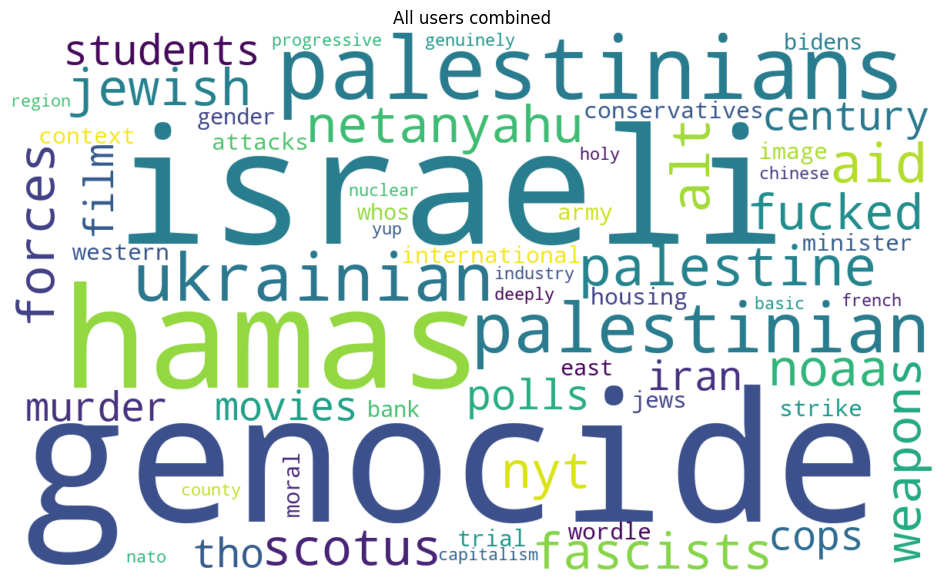

In [ ]:
def make_cloud(freqs, width=800, height=500):
    return WordCloud(
        width=width, height=height, background_color="white",
        max_words=60, collocations=False, colormap="viridis",
    ).generate_from_frequencies(freqs)

def user_freqs(user):
    sub = word_counts.filter(pl.col(USER_COL) == user)
    return dict(zip(sub["token"].to_list(), sub["n"].to_list()))

# Aggregate common tokens
overall = word_counts.group_by("token").agg(pl.col("n").sum())
overall_freqs = dict(zip(overall["token"].to_list(), overall["n"].to_list()))

plt.figure(figsize=(12, 7))
plt.imshow(make_cloud(overall_freqs, 1200, 700), interpolation="bilinear")
plt.axis("off")
plt.title("All users combined")
plt.show()

Get word cloud of top users with the most posts

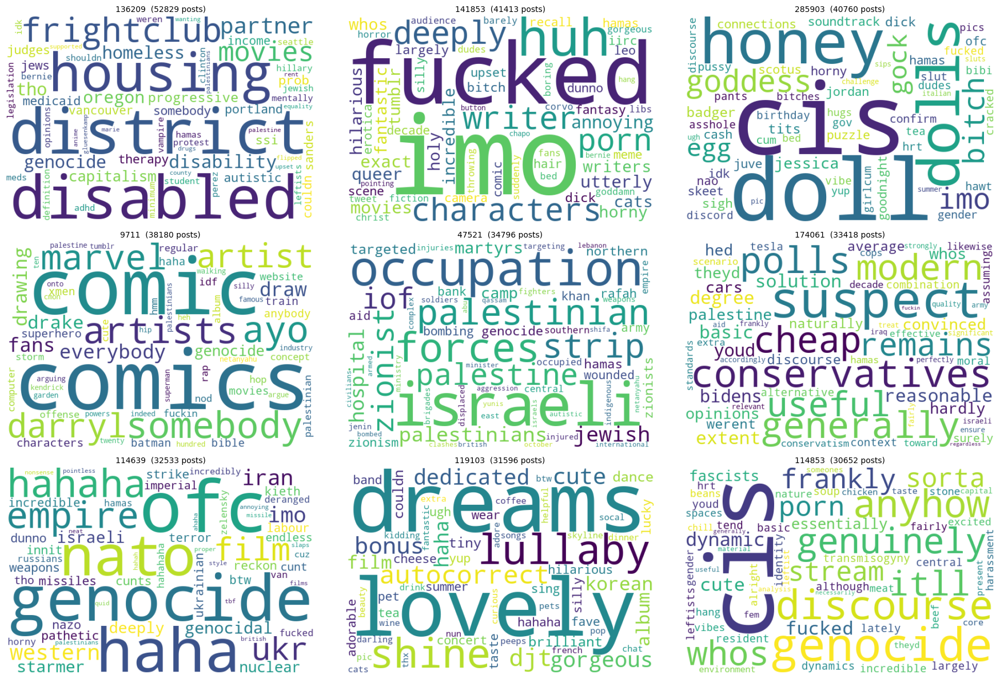

In [ ]:
posts_by_user = dict(zip(post_counts[USER_COL].to_list(), post_counts["posts"].to_list()))

def plot_user_grid(users, cols=GRID_COLS):
    rows = (len(users) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows), squeeze=False)
    axes = axes.flatten()
    for ax in axes:
        ax.axis("off")
    for ax, user in zip(axes, users):
        freqs = user_freqs(user)
        if not freqs:
            continue
        ax.imshow(make_cloud(freqs, 600, 400), interpolation="bilinear")
        ax.set_title(f"{str(user)[:28]}  ({posts_by_user[user]} posts)", fontsize=10)
    plt.tight_layout()
    plt.show()

top_users = post_counts.sort("posts", descending=True).head(TOP_USERS)[USER_COL].to_list()
plot_user_grid(top_users)

Get word cloud of random users

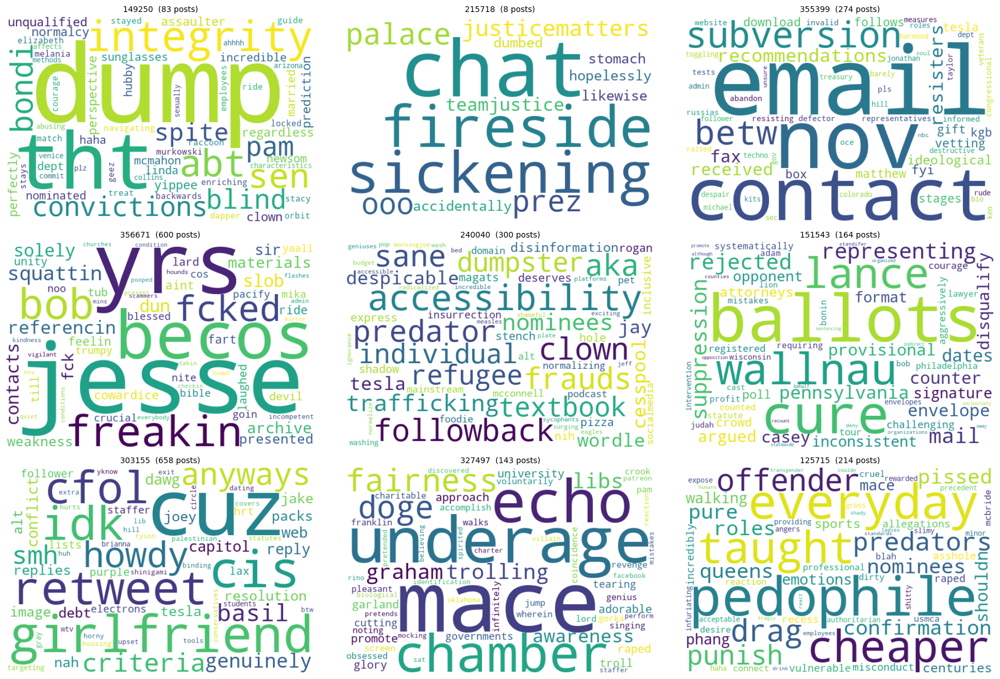

In [27]:
# Random sample of users
import random

random.seed(0)
sample_users = random.sample(list(posts_by_user), k=min(TOP_USERS, len(posts_by_user)))
plot_user_grid(sample_users)

Get the word cloud of an individual user

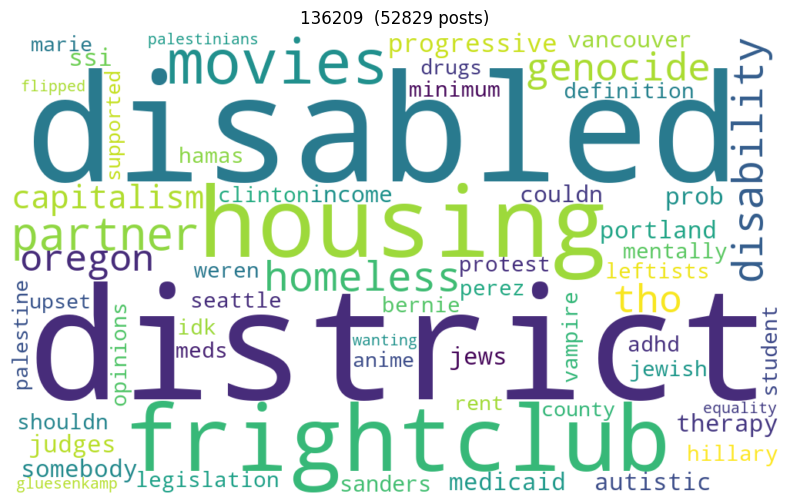

Content
str


In [32]:
# Get an individual user
USER_ID = top_users[0]

plt.figure(figsize=(10, 6))
plt.imshow(make_cloud(user_freqs(USER_ID), 1000, 600), interpolation="bilinear")
plt.axis("off")
plt.title(f"{USER_ID}  ({posts_by_user[USER_ID]} posts)")
plt.show()

df.filter(pl.col(USER_COL) == USER_ID).select(TEXT_COL).head(8)

In [ ]:
# Get distinct word per user
top_words = (
    word_counts.sort("n", descending=True)
    .group_by(USER_COL)
    .agg(
        pl.col("token").n_unique().alias("distinct_words"),
        pl.col("token").head(10).str.join(", ").alias("top_words"),
    )
    .join(post_counts, on=USER_COL)
    .sort("posts", descending=True)
    .select(USER_COL, "posts", "distinct_words", "top_words")
)
top_words.head(30)

UserId,posts,distinct_words,top_words
i64,u32,u32,str
136209,52829,19527,"""district, disabled, housing, f…"
141853,41413,27522,"""imo, fucked, huh, deeply, writ…"
285903,40760,21284,"""cis, doll, honey, dolls, godde…"
9711,38180,23479,"""comics, comic, somebody, ayo, …"
47521,34796,22487,"""israeli, occupation, forces, p…"
…,…,…,…
39692,19831,18757,"""incredible, cops, reagan, film…"
253818,19620,19799,"""website, movies, trek, annoyin…"
232671,19536,15774,"""labour, reform, conservatives,…"


#### Word Cloud using User Networks

The word clouds are formed according to the following goals:
- The data will be filtered according to users with the most connections
- Their strongest connections will be mapped, and compare if there are similar things they talk about


In [ ]:
# Network configurations
NET_SRC = "SourceUserId"
NET_DST = "TargetUserId"
NET_TYPE = "InteractionType"
NET_COUNT = "Count"

INTERACTION_TYPES = ["Quote"] # None = all, repost, like, quote
DIRECTION = "out" # "both", "in" (hub is the target), or "out" (hub is the source)
HUB_RANK_BY = "degree" # "degree" = number of distinct connections, "weight" = sum of Count
N_HUBS = 4
N_NEIGHBORS = 8 # strongest connections (by Count) shown for each hub
TOP_K_OVERLAP = 20 # compare each pair's top-K words
RANDOM_BASELINE = 50 # random users used to see what "chance" overlap looks like

# NOTE: Hub corresponds to the user ID where the word cloud will come from

In [ ]:
# Check InteractionType
network = user_network_df

if NET_TYPE in network.columns:
    agg = [pl.len().alias("edges")]
    if NET_COUNT in network.columns:
        agg.append(pl.col(NET_COUNT).sum().alias("total_count"))
    type_summary = network.group_by(NET_TYPE).agg(agg).sort("edges", descending=True)
else:
    type_summary = "No interaction type column found; all edges are treated alike."
type_summary

InteractionType,edges,total_count
str,u32,i64
"""Like""",991317,7609970
"""Repost""",525080,2406855
"""Quote""",160498,599323


In [ ]:
# NOTE: There is no replies in the user network, would only have to rely on these types for now

The code below is for building the hub, neighbor, and weight pairs. Each user ID in `net` will matched with the ones in the user posts table

In [ ]:
# Build (hub, neighbor, weight) pairs. IDs are cast to the type of UserId so the tables match.
uid_type = df.schema[USER_COL] # get user ids in the user_post_history_df

net = network.select(
    pl.col(NET_SRC).cast(uid_type).alias("src"),
    pl.col(NET_DST).cast(uid_type).alias("dst"),
    (pl.col(NET_TYPE).cast(pl.Utf8) if NET_TYPE in network.columns else pl.lit("all")).alias("itype"),
    (pl.col(NET_COUNT).cast(pl.Float64).fill_null(1.0) if NET_COUNT in network.columns else pl.lit(1.0)).alias("w"),
)

if INTERACTION_TYPES:
    net = net.filter(pl.col("itype").is_in([str(t) for t in INTERACTION_TYPES]))

net = net.filter(pl.col("src") != pl.col("dst"))   # drop self-connections

fwd = net.select(pl.col("src").alias("hub"), pl.col("dst").alias("nbr"), "w") # hub is the source
bwd = net.select(pl.col("dst").alias("hub"), pl.col("src").alias("nbr"), "w") # hub is the target

if DIRECTION == "out":
    pairs = fwd
elif DIRECTION == "in":
    pairs = bwd
else:
    pairs = pl.concat([fwd, bwd])

pairs = pairs.group_by("hub", "nbr").agg(pl.col("w").sum())
print(f"{net.height:,} edges -> {pairs.height:,} (hub, neighbor) pairs")

157,096 edges -> 298,160 (hub, neighbor) pairs


**Pick the hubs.** Only users who also have enough text in the post table can be hubs, since a word cloud needs posts. The `neighbors_with_text` column shows how many of each hub's connections have posts to look at.

Very high-degree accounts may be news outlets, celebrities, or bots, and their neighbors can be a mixed crowd. Check the hub IDs before interpreting.

In [81]:
# Most connections, among users who have enough text (post_counts)
degree = pairs.group_by("hub").agg(
    pl.len().alias("n_connections"),
    pl.col("w").sum().alias("total_weight"),
)
rank_col = "n_connections" if HUB_RANK_BY == "degree" else "total_weight"

has_text = post_counts.rename({USER_COL: "hub"})
hubs = (
    degree.join(has_text, on="hub")
    .sort(rank_col, descending=True)
    .head(N_HUBS)
)

nbr_text = post_counts.rename({USER_COL: "nbr", "posts": "nbr_posts"})
with_text = (
    pairs.join(hubs.select("hub"), on="hub", how="semi")
    .join(nbr_text, on="nbr")
    .group_by("hub").agg(pl.len().alias("neighbors_with_text"))
)
hubs = hubs.join(with_text, on="hub", how="left").sort(rank_col, descending=True)

print(f"{degree.height:,} users appear in the network; "
      f"{degree.join(has_text, on='hub').height:,} of them have enough text")
hubs

7,189 users appear in the network; 2,475 of them have enough text


hub,n_connections,total_weight,posts,neighbors_with_text
i64,u32,f64,u32,u32
31639,1711,12049.0,3912,610
194290,1481,14106.0,3060,531
247716,1206,5511.0,5124,416
363863,1095,1993.0,748,377


Pick each hub's strongest connections

In [82]:
nbrs = (
    pairs.join(hubs.select("hub"), on="hub", how="semi")
    .join(nbr_text, on="nbr")
    .sort(["hub", "w"], descending=[False, True])
    .group_by("hub", maintain_order=True).head(N_NEIGHBORS)
)

sel_users = pl.concat([
    hubs.select(pl.col("hub").alias(USER_COL)),
    nbrs.select(pl.col("nbr").alias(USER_COL)),
]).unique()

# reuse the word counts already built in the notebook
net_wc = word_counts.filter(pl.col(USER_COL).is_in(sel_users[USER_COL].to_list()))
print(f"{sel_users.height} users selected (hubs + neighbors)")
nbrs.head(20)

34 users selected (hubs + neighbors)


hub,nbr,w,nbr_posts
i64,i64,f64,u32
31639,401074,206.0,18361
31639,80495,124.0,20419
31639,346701,99.0,7335
31639,173330,84.0,1788
31639,115154,82.0,5171
…,…,…,…
194290,67960,85.0,11202
247716,174061,82.0,33418
247716,401074,65.0,18361


In [ ]:
# -- Word cloud function --
def plot_cloud_items(items, cols=3):
    rows = (len(items) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows), squeeze=False)
    axes = axes.flatten()
    for ax in axes:
        ax.axis("off")
    for ax, (title, freqs) in zip(axes, items):
        if freqs:
            ax.imshow(make_cloud(freqs, 600, 400), interpolation="bilinear")
        ax.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.show()

**Show the word cloud of the hub and its connections**

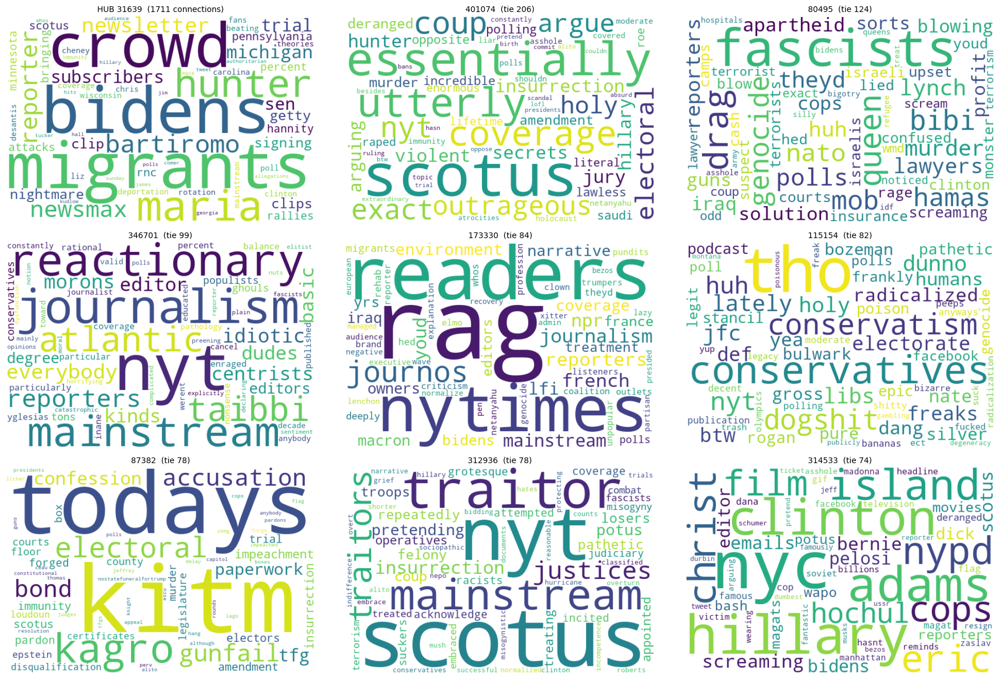

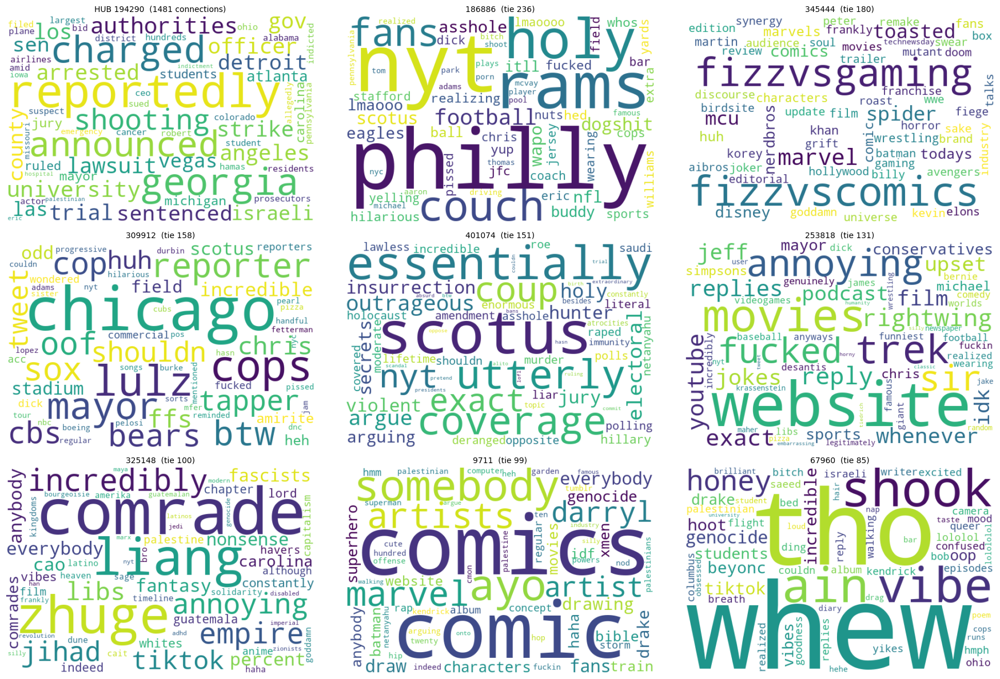

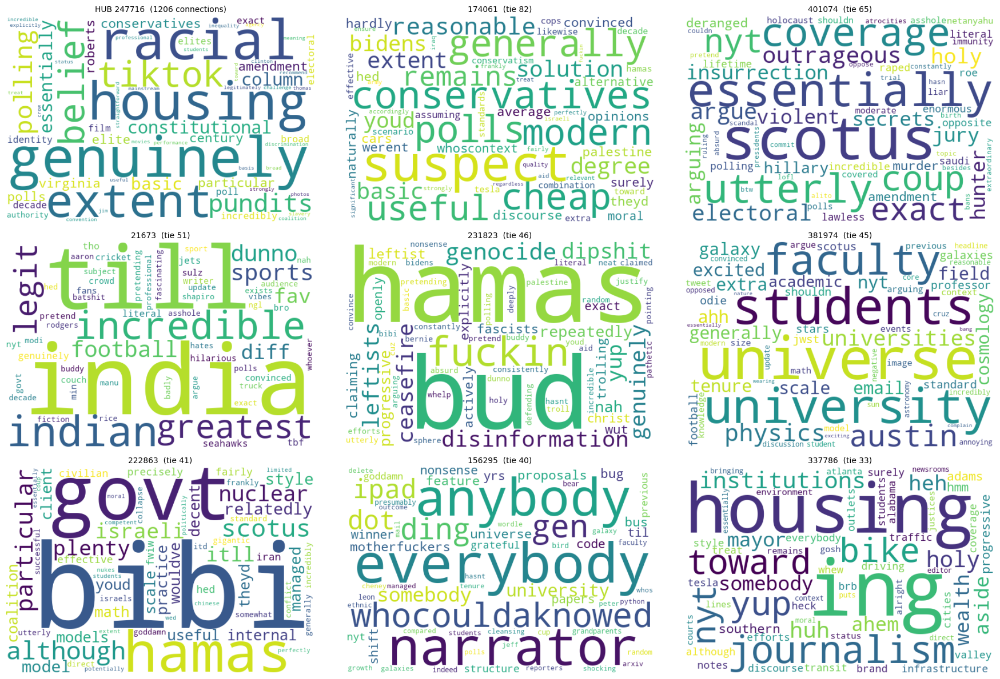

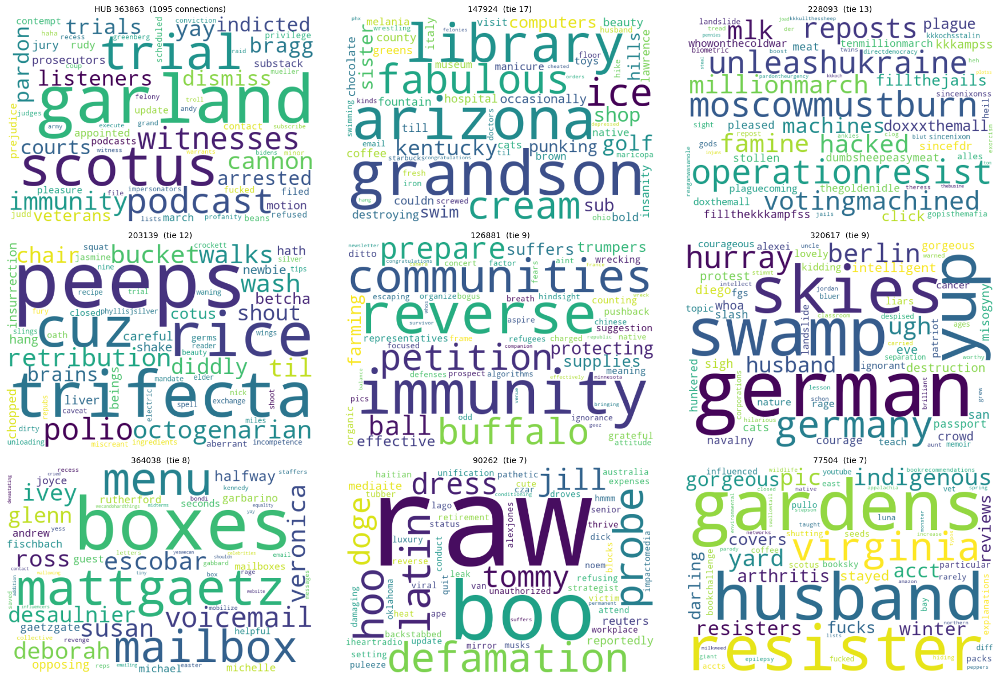

In [ ]:
for r in hubs.iter_rows(named=True):
    h = r["hub"]
    hn = nbrs.filter(pl.col("hub") == h)
    items = [(f"HUB {str(h)[:24]}  ({r['n_connections']} connections)", user_freqs(h))]
    items += [
        (f"{str(x['nbr'])[:24]}  (tie {x['w']:g})", user_freqs(x["nbr"]))
        for x in hn.iter_rows(named=True)
    ]
    plot_cloud_items(items)

**Show the word cloud of the hub and its combined connections**

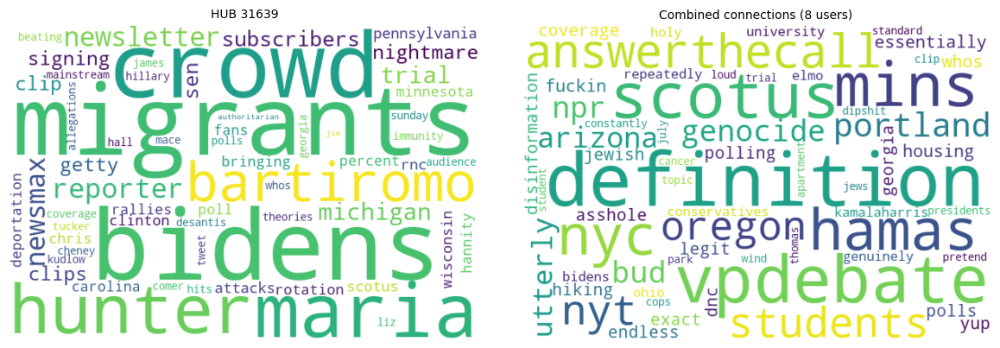

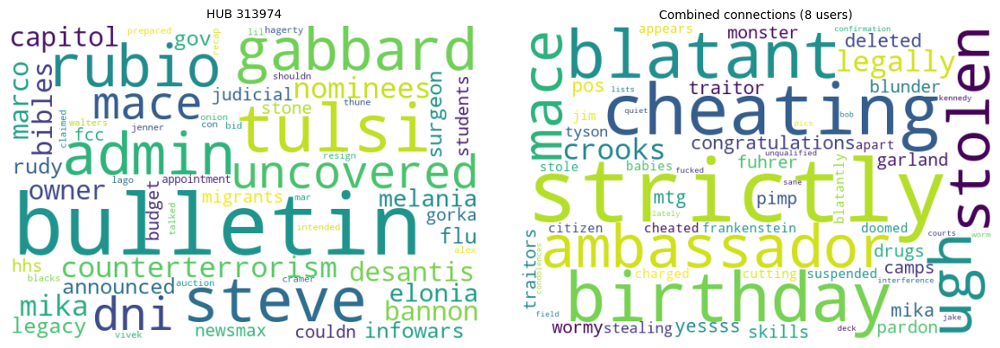

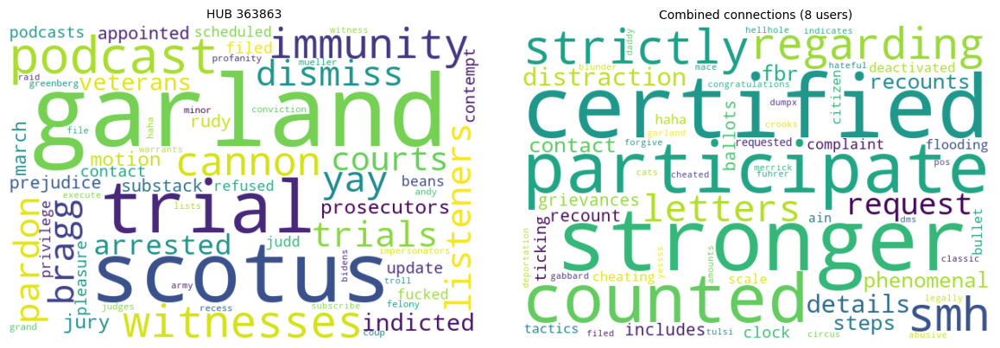

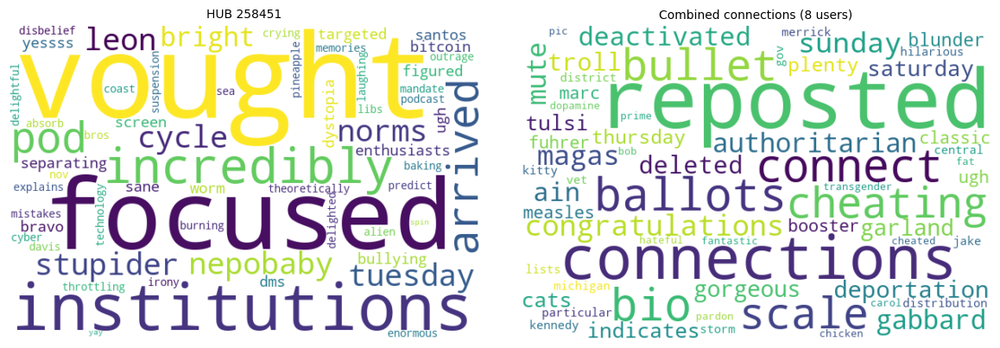

In [77]:
# Each user's counts become shares first, so one heavy poster does not dominate
net_share = net_wc.with_columns((pl.col("n") / pl.col("n").sum().over(USER_COL)).alias("share"))

def combined_freqs(users):
    sub = net_share.filter(pl.col(USER_COL).is_in(users)).group_by("token").agg(pl.col("share").sum())
    return dict(zip(sub["token"].to_list(), sub["share"].to_list()))

for r in hubs.iter_rows(named=True):
    h = r["hub"]
    nb_ids = nbrs.filter(pl.col("hub") == h)["nbr"].to_list()
    plot_cloud_items(
        [(f"HUB {str(h)[:24]}", user_freqs(h)),
         (f"Combined connections ({len(nb_ids)} users)", combined_freqs(nb_ids))],
        cols=2,
    )